# Models, planning, Dyna: implementation

Dyna-Q, Dyna-Q+ and prioritized sweeping on the chapter's mazes, and the comparison of full and sample backups, each checked against exact shortest paths, value iteration, linear solves or a closed-form error.
Companion to the chapter note: [Models, planning, Dyna](../chapters/08a%20Models%2C%20planning%2C%20Dyna.md).

**Sections**
1. The Dyna maze and what can be computed exactly
2. Dyna-Q on the Dyna maze
3. The policies after the second episode
4. When the model is wrong: Dyna-Q+ on the blocking and shortcut mazes
5. Prioritized sweeping
6. Full versus sample backups
7. Checkpoints

**Not implemented**
- The rod-maneuvering task: the chapter gives its actions (translations of about 1/20 of the workspace, 10-degree rotations), its size (20 x 20 positions, 14,400 states) and a figure of the solution, but not the obstacles, so the task cannot be rebuilt.
- The Dyna-AC agent: the chapter names it (a Dyna agent with an actor-critic learner) without specifying it. The third agent in the changing-maze comparison is therefore plain Q-learning without planning.
- Prioritized sweeping for stochastic environments: the chapter only describes it in words.

A *backup* is an update of a value estimate toward a value computed from successor estimates; a *model* predicts the next reward and next state for a state-action pair; *planning* applies backups to experience the model simulates.
The chapter note defines these and the other terms in full.

In [1]:
import heapq
from collections.abc import Iterator

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy import stats

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_DYNA, SEED_POLICY, SEED_CHANGE, SEED_SWEEP, SEED_BACKUP = 81, 82, 83, 84, 85
MOVES = ((-1, 0), (1, 0), (0, 1), (0, -1))
ARROWS = "↑↓→←"
CHUNK = 1 << 14  # random numbers drawn per batch
GAMMA, ALPHA, EPS = 0.95, 0.1, 0.1
PLAN_STEPS = (0, 5, 50)
N_REPS, N_EPISODES = 30, 50
EPISODE_MARKS = (2, 3, 4, 5, 10, 15, 20, 25, 30, 40, 50)  # episodes at which mean steps are printed
PLATEAU_FROM = 41  # the late window is episodes 41 to 50
Z_CLAIM = 3  # standard errors a single comparison must exceed, or a mean may stay within
FWER = 0.05  # family-wise error rate for the Bonferroni limits on many simultaneous comparisons
DYNA_MAZE = (
    ".......#G",
    "..#....#.",
    "S.#....#.",
    "..#......",
    ".....#...",
    ".........",
)
BLOCK_BEFORE = ("........G", ".........", ".........", "########.", ".........", "...S.....")
BLOCK_AFTER = ("........G", ".........", ".........", ".########", ".........", "...S.....")
SHORT_BEFORE = ("........G", ".........", ".........", ".########", ".........", "...S.....")
SHORT_AFTER = ("........G", ".........", ".........", ".#######.", ".........", "...S.....")
CHANGE_REPS, CHANGE_PLAN, CHANGE_ALPHA, KAPPA = 30, 10, 1.0, 1e-3
BLOCK_CHANGE_AT, BLOCK_HORIZON = 1000, 3000
SHORT_CHANGE_AT, SHORT_HORIZON = 3000, 6000
FINAL_WINDOW = 1000  # last time steps used to measure steps per episode
SWEEP_ALPHA, SWEEP_PLAN, THETA = 1.0, 5, 1e-4
SWEEP_SCALES, SWEEP_REPS = (1, 2, 3, 4), (30, 20, 12, 8)
SWEEP_MAX_STEPS = 150_000  # a run that has not found the optimal path by then is censored
BACKUP_B, BACKUP_REPS = (2, 10, 100, 1000), 2000
BACKUP_SHOWN_T = (1, 10, 100)  # printed for every b, besides t = b and t = 2b
SPREAD_PAIRS = (10, 100)  # pairs sharing the cost of one full backup in the budget comparison
CHECK_SUCCESSORS, CHECK_SAMPLES = 10, 40  # size of the single-pair check of the 1/t update
BOOK_FIRST_EPISODE, BOOK_STATES, BOOK_SHORTEST = 1700, 47, 14
BOOK_EPISODES, BOOK_SWEEP_RATIO = ("~25", "~5", "~3"), "5-10"
POLICY_STEPS, SNAPSHOT_EPISODE = (0, 50), 2  # SNAPSHOT_EPISODE is counted from 1
VALUE_TOL, TIE_TOL, AGREE_TOL = 1e-14, 1e-12, 1e-12
VI_SWEEPS, PLAN_PROBE_BACKUPS = 2000, 100_000  # value iteration sweeps and planning backups in the model check
PATH_LIMIT = 200  # longest greedy path followed, in steps
RESCORE_MARGINS = (5, 10)  # steps above a level in the alternative episodes-needed rules
STEPS_YLIM, POLICY_FIGSIZE, CHANGE_FIGSIZE = (0, 700), (10, 6.5), (11, 4)
CURVE_POINTS, BACKUP_YLIM = 200, (-0.04, 1.05)
AGENTS = {"no planning (n = 0)": (0, 0.0), "Dyna-Q": (CHANGE_PLAN, 0.0), "Dyna-Q+": (CHANGE_PLAN, KAPPA)}
TASKS = {
    "blocking": (BLOCK_BEFORE, BLOCK_AFTER, BLOCK_CHANGE_AT, BLOCK_HORIZON),
    "shortcut": (SHORT_BEFORE, SHORT_AFTER, SHORT_CHANGE_AT, SHORT_HORIZON),
}
BACKUP_T = (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000)  # sample counts tried (up to 2b, and b and 2b themselves)

## 1. The Dyna maze and what can be computed exactly

The maze is a grid of 6 rows and 9 columns with 7 wall cells, so 47 cells are states. The agent starts in S and wants to reach G.

- **Actions:** up, down, right, left move the agent to the neighboring cell; a move into a wall or off the grid leaves it where it is.
- **Reward:** +1 for entering G, 0 for every other step. After reaching G the agent returns to S and a new *episode* (one trip from S to G) begins.
- **Discount:** $\gamma = 0.95$, so a cell $d$ steps from G has optimal value $v_*(s) = \gamma^{d-1}$: the reward comes at the $d$-th step, discounted $d-1$ times.

The wall layout is read off the chapter's figure by eye: walls in column 3 (rows 2 to 4), in column 8 (rows 1 to 3) and one cell in row 5, column 6.

The environment is deterministic and small, so everything the learning agents should end up with can be computed exactly, without learning:

- **Shortest path** from S to G by breadth-first search outward from G.
- **Optimal action values** $q_*$ by value iteration, $q(s,a) \leftarrow r + \gamma \max_{a'} q(s', a')$ repeated to convergence; the closed form $\gamma^{d-1}$ above checks it against the search.
- **First episode length.** All values start at zero, so every action looks equally good and the agent moves as a uniform random walk until it first hits G. Its expected length solves the linear equations $h(s) = 1 + \sum_{s'} P(s' \mid s)\, h(s')$ over the non-goal cells (the standard deviation comes from a second such equation for the second moment), and the chance that it exceeds a given length follows from powers of the transition matrix.
- **The best an $\varepsilon$-greedy agent can do.** The $\varepsilon$-greedy policy with respect to $q_*$ picks a best action with probability $1-\varepsilon$ (split equally among ties) and a uniformly random action with probability $\varepsilon$. Its expected steps per episode, from the same linear equations, is the *$\varepsilon$-optimal level*, the reference for the learning curves: even a perfect agent that keeps exploring takes more steps than the shortest path.

In [2]:
class Maze:
    """A deterministic gridworld; `nxt[4 * s + a]` is the cell reached from cell s by action a, and entering the goal pays +1."""

    def __init__(self, rows: tuple[str, ...], scale: int = 1):
        chars = np.array([list(r) for r in rows])
        self.walls = np.kron(chars == "#", np.ones((scale, scale), dtype=bool))
        (sr, sc), (gr, gc) = (tuple(int(v) for v in np.argwhere(chars == ch)[0]) for ch in "SG")
        self.h, self.w = self.walls.shape
        self.start, self.goal = sr * scale * self.w + sc * scale, gr * scale * self.w + (gc + 1) * scale - 1
        self.nxt = [0] * (4 * self.n_cells)
        for s in range(self.n_cells):
            r, c = divmod(s, self.w)
            for a, (dr, dc) in enumerate(MOVES):
                r2, c2 = r + dr, c + dc
                open_ = 0 <= r2 < self.h and 0 <= c2 < self.w and not self.walls[r2, c2] and not self.walls[r, c]
                self.nxt[4 * s + a] = r2 * self.w + c2 if open_ else s

    @property
    def n_cells(self) -> int:
        return self.h * self.w

    @property
    def free(self) -> np.ndarray:
        return ~self.walls.ravel()

In [3]:
def shortest_distances(maze: Maze) -> np.ndarray:
    """Steps to the goal from every cell by breadth-first search outward from the goal (inf for walls)."""
    dist, frontier = np.full(maze.n_cells, np.inf), [maze.goal]
    dist[maze.goal] = 0
    while frontier:
        reached = []
        for s in frontier:
            for a in range(4):
                s2 = maze.nxt[4 * s + a]
                if dist[s2] == np.inf:
                    dist[s2] = dist[s] + 1
                    reached.append(s2)
        frontier = reached
    return dist


def optimal_q(maze: Maze, gamma: float = GAMMA, tol: float = VALUE_TOL) -> np.ndarray:
    """q_* of every cell and action by value iteration on the known model (the goal's value is 0)."""
    nxt = np.array(maze.nxt).reshape(-1, 4)
    reward, V = (nxt == maze.goal).astype(float), np.zeros(maze.n_cells)
    while True:
        Q = reward + gamma * V[nxt]
        V_new = Q.max(axis=1)
        V_new[maze.goal] = 0.0
        if np.abs(V_new - V).max() < tol:
            return Q
        V = V_new

In [4]:
def transition_matrix(maze: Maze, pi: np.ndarray) -> np.ndarray:
    """State-to-state probabilities of the policy `pi[cell, action]`, with the goal absorbing (its row is all zero)."""
    nxt, P = np.array(maze.nxt).reshape(-1, 4), np.zeros((maze.n_cells, maze.n_cells))
    for a in range(4):
        np.add.at(P, (np.arange(maze.n_cells), nxt[:, a]), pi[:, a])
    P[maze.goal] = 0.0
    return P


def expected_steps(maze: Maze, pi: np.ndarray) -> np.ndarray:
    """Expected steps to the goal from every cell under `pi`, from the linear equations h = 1 + P h on the open cells."""
    P, keep = transition_matrix(maze, pi), np.flatnonzero(maze.free & (np.arange(maze.n_cells) != maze.goal))
    h = np.zeros(maze.n_cells)
    h[keep] = np.linalg.solve(np.eye(len(keep)) - P[np.ix_(keep, keep)], np.ones(len(keep)))
    return h


def steps_sd(maze: Maze, pi: np.ndarray) -> np.ndarray:
    """Standard deviation of the steps to the goal from every cell under `pi`, from the second moment h2 = 1 + 2 P h + P h2."""
    P, h = transition_matrix(maze, pi), expected_steps(maze, pi)
    keep = np.flatnonzero(maze.free & (np.arange(maze.n_cells) != maze.goal))
    h2 = np.zeros(maze.n_cells)
    h2[keep] = np.linalg.solve(np.eye(len(keep)) - P[np.ix_(keep, keep)], (1 + 2 * P @ h)[keep])
    return np.sqrt(h2 - h**2)


def survival(maze: Maze, pi: np.ndarray, t: int) -> float:
    """Exact probability that an episode from the start is still running after `t` steps under `pi`."""
    P, p = transition_matrix(maze, pi), np.zeros(maze.n_cells)
    p[maze.start] = 1.0
    for _ in range(t):
        p = p @ P
    return float(p.sum())

In [5]:
def eps_greedy_policy(Q: np.ndarray, eps: float) -> np.ndarray:
    """Action probabilities of the epsilon-greedy policy for `Q`, the greedy share split equally among tied actions."""
    best = np.isclose(Q, Q.max(axis=1, keepdims=True), rtol=0, atol=TIE_TOL)
    return eps / 4 + (1 - eps) * best / best.sum(axis=1, keepdims=True)


def z_limit(k: int) -> float:
    """Bonferroni limit in standard errors for `k` simultaneous two-sided comparisons at family-wise level FWER."""
    return float(stats.norm.isf(FWER / (2 * k)))

In [6]:
maze = Maze(DYNA_MAZE)
dist, q_star = shortest_distances(maze), optimal_q(maze)
d_star, v_star = int(dist[maze.start]), q_star.max(axis=1)
open_cells = np.flatnonzero(maze.free & (np.arange(maze.n_cells) != maze.goal))
uniform = np.full((maze.n_cells, 4), 0.25)
h_random, sd_random = expected_steps(maze, uniform)[maze.start], steps_sd(maze, uniform)[maze.start]
h_eps_opt = expected_steps(maze, eps_greedy_policy(q_star, EPS))[maze.start]
p_long = survival(maze, uniform, BOOK_FIRST_EPISODE)
print(
    f"States: {maze.free.sum()} ({maze.walls.sum()} wall cells of {maze.n_cells} are not states); start {divmod(maze.start, maze.w)}, goal {divmod(maze.goal, maze.w)}"
)
print(f"Shortest path from the start by breadth-first search: {d_star} steps")
print(
    f"Value iteration: v_*(start) = {v_star[maze.start]:.6f}; closed form gamma^({d_star}-1) = {GAMMA ** (d_star - 1):.6f}"
)
print(
    f"Value iteration against breadth-first search, largest difference over the {len(open_cells)} open cells: {np.abs(v_star[open_cells] - GAMMA ** (dist[open_cells] - 1)).max():.2e}"
)
print(
    f"Expected steps of the first episode (all values zero, so every action is equally likely): {h_random:.1f}; standard deviation {sd_random:.1f}; P(more than {BOOK_FIRST_EPISODE} steps) = {p_long:.3f}"
)
print(f"Expected steps per episode under the epsilon-greedy policy for q_*: {h_eps_opt:.2f} (epsilon = {EPS})")
maze_ok = (
    d_star == BOOK_SHORTEST
    and maze.free.sum() == BOOK_STATES
    and bool(np.allclose(v_star[open_cells], GAMMA ** (dist[open_cells] - 1), atol=AGREE_TOL))
)
print(
    "Checkpoint: 47 states, a shortest path of 14 steps as in the book's figure, and v_* = gamma^(d-1) in every open cell:",
    maze_ok,
)

States: 47 (7 wall cells of 54 are not states); start (2, 0), goal (0, 8)
Shortest path from the start by breadth-first search: 14 steps
Value iteration: v_*(start) = 0.513342; closed form gamma^(14-1) = 0.513342
Value iteration against breadth-first search, largest difference over the 46 open cells: 1.11e-16
Expected steps of the first episode (all values zero, so every action is equally likely): 868.7; standard deviation 789.2; P(more than 1700 steps) = 0.128
Expected steps per episode under the epsilon-greedy policy for q_*: 15.88 (epsilon = 0.1)
Checkpoint: 47 states, a shortest path of 14 steps as in the book's figure, and v_* = gamma^(d-1) in every open cell: True


### Reading the result

- The 47 states, the shortest path of 14 steps (the lowest mark on the chapter's learning-curve axis) and $v_*(\text{start}) = 0.513342 = \gamma^{13}$ agree. Value iteration and the breadth-first closed form differ by at most 1.11e-16 over the 46 open cells: two independent routes to the same numbers.
- A random walk needs 868.7 steps on average (standard deviation 789.2) to find G for the first time, and the chance that a first episode exceeds 1700 steps is 0.128 (exact, from the transition matrix). The chapter says the first episode takes about 1700 steps; the learning runs of the next section compare this with it.
- An $\varepsilon$-greedy agent that knows $q_*$ still needs 15.88 steps per episode on average (with $\varepsilon = 0.1$), against 14 for the shortest path. The learning curves below are compared with this level.

## 2. Dyna-Q on the Dyna maze

Dyna-Q learns from real experience in two ways and then also plans. In every real step the agent, in state $S$:

1. picks $A$ by $\varepsilon$-greedy with respect to $Q$ (a greedy action with probability $1-\varepsilon$, ties broken at random, otherwise a random action) and observes $R$ and $S'$;
2. **direct RL** (reinforcement learning from real experience): one Q-learning backup of the pair $(S,A)$;
3. **model learning**: stores $\mathrm{Model}(S,A) \leftarrow R, S'$, assuming a deterministic environment (the entry is overwritten by the latest observation);
4. **planning**, $n$ times: picks a previously observed state and a previously taken action in it at random, reads $R, S'$ from the model, and applies the same backup to this simulated transition.

$$
Q(S,A) \leftarrow Q(S,A) + \alpha \Big[ R + \gamma \max_a Q(S',a) - Q(S,A) \Big]
$$

- With $n = 0$ there is no model-learning or planning step left: it is one-step tabular Q-learning, the baseline.
- The model is never asked about a pair the agent has not experienced, so planning backups only ever use real transitions; they just reuse them many times.

Setup as in the chapter: $\alpha = 0.1$, $\varepsilon = 0.1$, initial values 0, $\gamma = 0.95$, $n = 0, 5, 50$, 30 repetitions of 50 episodes (no scale-down). Where this notebook makes a choice the chapter leaves open:

- **Two random streams per run.** One generator draws the acting choices (exploration, tie-breaking), another draws the planning choices. A run with a given seed therefore sees the same acting draws whatever $n$ is: the three values of $n$ are *paired* by seed, as the chapter's "same initial seed for every algorithm" requires. The generators come from `np.random.SeedSequence(SEED_DYNA).spawn`, one child per repetition.
- **The first episode** ends at the first arrival in G. While all values are zero a backup changes nothing, so the first episode must come out identical for every $n$; the output below checks that. Its expected length and standard deviation are known exactly (see the exact truths above), so the first-episode check uses the exact standard error.
- **The goal state** is terminal with value 0 and is never a starting pair for a backup.

How the learning curves are summarized (the chapter says "about 25, 5 and 3 episodes" without a rule):

- the *late level* of an agent is its mean steps over episodes 41 to 50;
- the *standard error* of a mean is the standard deviation across runs divided by the square root of the number of runs; the one used here is that of a per-episode mean over the 30 runs, averaged over the late episodes;
- an agent has *reached* its late level in the first episode whose 30-run mean is at or below the late level plus 3 standard errors, and it *stays* there from the first episode after which all later episodes are at or below it;
- the output also gives $z$, a difference divided by its standard error.
- because the chapter gives no rule, the output re-scores the same means with looser rules (late level plus 5 or 10 steps; the exact $\varepsilon$-optimal level plus 10 steps) and prints in brackets the number of *learning* episodes before the settling episode, since the chapter counts learning episodes (it says a complete policy exists "by the end of the third episode").

One more check isolates the planning step. After the runs, planning backups alone (step size 1, many of them) are applied to the model that one run learned, and the result is compared with value iteration on that same model. The *Bellman residual* is the largest gap between a pair's value and its one-step backup under the model; the distance of the values from the model's exact solution is at most the residual divided by $1-\gamma$, which gives the tolerance.

In [7]:
def uniforms(rng: np.random.Generator) -> Iterator[float]:
    """Endless stream of uniform random numbers on [0, 1) drawn in batches."""
    while True:
        yield from rng.random(CHUNK).tolist()


def rep_rngs(seed: int, n: int) -> list[tuple[np.random.Generator, np.random.Generator]]:
    """`n` pairs (acting generator, planning generator) from a fresh SeedSequence, so equal seeds always give equal pairs."""
    return [tuple(np.random.default_rng(c) for c in ss.spawn(2)) for ss in np.random.SeedSequence(seed).spawn(n)]


class Agent:
    """Tabular action values Q, a deterministic model and epsilon-greedy acting; `learn` is added by the subclasses."""

    def __init__(
        self,
        n_cells: int,
        rng_act: np.random.Generator,
        rng_plan: np.random.Generator,
        alpha: float = ALPHA,
        gamma: float = GAMMA,
        eps: float = EPS,
    ):
        self.Q, self.model_s, self.model_r = [0.0] * (4 * n_cells), [-1] * (4 * n_cells), [0.0] * (4 * n_cells)
        self.alpha, self.gamma, self.eps, self.backups = alpha, gamma, eps, 0
        self.u_act, self.u_plan = uniforms(rng_act), uniforms(rng_plan)

    def act(self, s: int) -> int:
        """Epsilon-greedy action with respect to Q; ties among the greedy actions are broken at random."""
        explore, pick = next(self.u_act), next(self.u_act)
        if explore < self.eps:
            return int(pick * 4)
        q = self.Q[4 * s : 4 * s + 4]
        best = [a for a in range(4) if q[a] == max(q)]
        return best[int(pick * len(best))]

    def backup(self, i: int, r: float, s2: int) -> None:
        """One-step tabular Q-learning backup of the pair with index i = 4 s + a toward r + gamma max_a Q(s2, a)."""
        self.Q[i] += self.alpha * (r + self.gamma * max(self.Q[4 * s2 : 4 * s2 + 4]) - self.Q[i])
        self.backups += 1

In [8]:
class DynaQ(Agent):
    """Dyna-Q: direct RL, model learning and `n_plan` planning backups on previously observed pairs per real step."""

    def __init__(self, *args, n_plan: int, **kw):
        super().__init__(*args, **kw)
        n_cells = len(self.Q) // 4
        self.n_plan, self.visited, self.tried, self.t = n_plan, [], [[] for _ in range(n_cells)], 0

    def remember(self, i: int, r: float, s2: int) -> None:
        """Model learning: the entry for pair i becomes the last observed reward and next state."""
        s, a = divmod(i, 4)
        if not self.tried[s]:
            self.visited.append(s)
        if self.model_s[i] < 0:
            self.tried[s].append(a)
        self.model_s[i], self.model_r[i] = s2, r

    def plan(self) -> None:
        """One planning backup: a random previously observed state, a random action previously taken there, the model's answer."""
        s = self.visited[int(next(self.u_plan) * len(self.visited))]
        j = 4 * s + self.tried[s][int(next(self.u_plan) * len(self.tried[s]))]
        self.backup(j, self.model_r[j], self.model_s[j])

    def learn(self, s: int, a: int, r: float, s2: int, t: int) -> None:
        """One real step: direct backup, model update, then `n_plan` planning backups; `t` is the time step."""
        i = 4 * s + a
        self.t = t
        self.backup(i, r, s2)
        self.remember(i, r, s2)
        for _ in range(self.n_plan):
            self.plan()

In [9]:
def run_episodes(maze: Maze, agent: Agent, n_episodes: int, snap: frozenset = frozenset()) -> tuple[list[int], dict]:
    """Play episodes from the start; returns steps per episode and copies of Q after the (episode, step) pairs in `snap`."""
    steps, shots, s, t = [], {}, maze.start, 0
    for e in range(n_episodes):
        k = 0
        while s != maze.goal:
            a = agent.act(s)
            s2 = maze.nxt[4 * s + a]
            t, k = t + 1, k + 1
            agent.learn(s, a, float(s2 == maze.goal), s2, t)
            if (e, k) in snap:
                shots[(e, k)] = (list(agent.Q), s2)
            s = s2
        steps.append(k)
        s = maze.start
    return steps, shots

In [10]:
results = {}
for n in PLAN_STEPS:
    runs, agents = [], []
    for rng_act, rng_plan in rep_rngs(SEED_DYNA, N_REPS):
        agent = DynaQ(maze.n_cells, rng_act, rng_plan, n_plan=n)
        runs.append(run_episodes(maze, agent, N_EPISODES)[0])
        agents.append(agent)
    results[n] = (np.array(runs), agents)
steps = {n: results[n][0] for n in PLAN_STEPS}
mean_steps = {n: steps[n].mean(axis=0) for n in PLAN_STEPS}
first_equal = all((steps[n][:, 0] == steps[0][:, 0]).all() for n in PLAN_STEPS)
first_mean = steps[0][:, 0].mean()
first_se = steps[0][:, 0].std(ddof=1) / np.sqrt(N_REPS)
first_se = sd_random / np.sqrt(N_REPS)  # exact standard error of a mean of N_REPS first episodes
print(
    f"First episode, mean steps over {N_REPS} repetitions {first_mean:.1f}; exact expectation {h_random:.1f} with exact standard error {first_se:.1f} (z = {(first_mean - h_random) / first_se:+.1f}); "
    f"the book's {BOOK_FIRST_EPISODE} is {(BOOK_FIRST_EPISODE - h_random) / first_se:.1f} such standard errors above the expectation; a mean up to {h_random + Z_CLAIM * first_se:.0f} would pass the {Z_CLAIM}-standard-error check; identical for every n: {first_equal}"
)
print("Mean steps per episode:  episode " + " ".join(f"{e:>6}" for e in EPISODE_MARKS))
for n in PLAN_STEPS:
    print(f"  n = {n:<2}                     " + " ".join(f"{mean_steps[n][e - 1]:>6.1f}" for e in EPISODE_MARKS))
model_exact = all(
    agent.model_s[i] == maze.nxt[i] and agent.model_r[i] == float(maze.nxt[i] == maze.goal)
    for n in PLAN_STEPS
    for agent in results[n][1]
    for i in range(len(agent.Q))
    if agent.model_s[i] >= 0
)
print(
    "Checkpoint: the first episode is identical for every n (planning does nothing while all values are zero):",
    first_equal,
)
print("Checkpoint: every learned model entry equals the true transition:", model_exact)

First episode, mean steps over 30 repetitions 1088.1; exact expectation 868.7 with exact standard error 144.1 (z = +1.5); the book's 1700 is 5.8 such standard errors above the expectation; a mean up to 1301 would pass the 3-standard-error check; identical for every n: True
Mean steps per episode:  episode      2      3      4      5     10     15     20     25     30     40     50
  n = 0                       509.6  586.7  413.5  217.1  121.3  100.0   71.3   27.7   19.2   17.4   18.4
  n = 5                       142.2   58.7   32.7   24.5   16.9   16.9   16.7   16.8   16.5   16.3   16.3
  n = 50                       40.5   18.0   16.6   16.5   17.1   16.2   16.6   16.1   16.7   15.6   16.1
Checkpoint: the first episode is identical for every n (planning does nothing while all values are zero): True
Checkpoint: every learned model entry equals the true transition: True


In [11]:
def model_arrays(agent: Agent) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """The agent's model as arrays: which pairs are observed, their next cells and their rewards (shape cells x 4)."""
    return (
        np.array(agent.model_s).reshape(-1, 4) >= 0,
        np.maximum(agent.model_s, 0).reshape(-1, 4),
        np.array(agent.model_r).reshape(-1, 4),
    )


def model_backup(Q: np.ndarray, model: tuple, gamma: float = GAMMA) -> np.ndarray:
    """Full backup of every observed pair of the agent's model (unobserved pairs keep value 0)."""
    seen, nxt, r = model
    return np.where(seen, r + gamma * Q.max(axis=1)[nxt], 0.0)


probe = results[0][1][0]
model = model_arrays(probe)
Q_before = np.array(probe.Q).reshape(-1, 4)
Q_vi = np.zeros_like(Q_before)
for _ in range(VI_SWEEPS):
    Q_vi = model_backup(Q_vi, model)
probe.alpha = 1.0
for _ in range(PLAN_PROBE_BACKUPS):
    probe.plan()
Q_plan = np.array(probe.Q).reshape(-1, 4)
res_before, res_after = (np.abs(model_backup(Q, model) - Q)[model[0]].max() for Q in (Q_before, Q_plan))
gap = np.abs(Q_plan - Q_vi)[model[0]].max()
plan_ok = gap <= res_after / (1 - GAMMA) + AGREE_TOL and res_after < res_before
print(
    f"One n = 0 run's learned model, {model[0].sum()} observed pairs: Bellman residual of its Q {res_before:.3f} before and {res_after:.1e} after {PLAN_PROBE_BACKUPS:,} planning backups with step size 1"
)
print(
    f"Value iteration on the same model: largest difference from the planned Q {gap:.1e}, within the bound residual / (1 - gamma) = {res_after / (1 - GAMMA):.1e}; largest value {Q_plan.max():.4f}"
)
print(
    "Checkpoint: planning backups reach the value-iteration solution of the learned model, within the bound the residual implies:",
    plan_ok,
)

One n = 0 run's learned model, 184 observed pairs: Bellman residual of its Q 0.872 before and 0.0e+00 after 100,000 planning backups with step size 1
Value iteration on the same model: largest difference from the planned Q 0.0e+00, within the bound residual / (1 - gamma) = 0.0e+00; largest value 1.0000
Checkpoint: planning backups reach the value-iteration solution of the learned model, within the bound the residual implies: True


In [12]:
late = {n: steps[n][:, PLATEAU_FROM - 1 :] for n in PLAN_STEPS}
late_se = {n: np.sqrt(late[n].var(axis=0, ddof=1).mean() / N_REPS) for n in PLAN_STEPS}
plateau = {n: late[n].mean(axis=1) for n in PLAN_STEPS}
plateau_z = {n: (plateau[n].mean() - h_eps_opt) / (plateau[n].std(ddof=1) / np.sqrt(N_REPS)) for n in PLAN_STEPS}
threshold = {n: plateau[n].mean() + Z_CLAIM * late_se[n] for n in PLAN_STEPS}


def episodes_needed(mean_per_episode: np.ndarray, limit: float) -> tuple[int | None, int | None]:
    """First episode (counted from 1) at or below `limit`, and the first from which every later episode stays at or below it."""
    ok = mean_per_episode <= limit
    first = int(np.argmax(ok)) + 1 if ok.any() else None
    stays = next((e + 1 for e in range(len(ok)) if ok[e:].all()), None)
    return first, stays


needed = {n: episodes_needed(mean_steps[n], threshold[n]) for n in PLAN_STEPS}
print(
    f"Late level of each agent = mean steps over episodes {PLATEAU_FROM}-{N_EPISODES}; exact epsilon-optimal level {h_eps_opt:.2f}"
)
for n in PLAN_STEPS:
    print(
        f"  n = {n:<2} late level {plateau[n].mean():.2f} (excess over the exact level {plateau[n].mean() - h_eps_opt:+.2f}, {plateau_z[n]:+.1f} standard errors); "
        f"reached below {threshold[n]:.2f} (late level + {Z_CLAIM} x {late_se[n]:.2f}): first episode below {needed[n][0]}, stays below from episode {needed[n][1]}"
    )

Late level of each agent = mean steps over episodes 41-50; exact epsilon-optimal level 15.88
  n = 0  late level 17.74 (excess over the exact level +1.86, +6.4 standard errors); reached below 19.53 (late level + 3 x 0.60): first episode below 27, stays below from episode 30
  n = 5  late level 16.62 (excess over the exact level +0.74, +3.2 standard errors); reached below 17.91 (late level + 3 x 0.43): first episode below 7, stays below from episode 7
  n = 50 late level 16.20 (excess over the exact level +0.32, +1.7 standard errors); reached below 17.43 (late level + 3 x 0.41): first episode below 4, stays below from episode 4


Episode from which the mean stays below the level, by rule (learning episodes before it in brackets, as the book counts):
  late level + 3 standard errors                n = 0: 30 (29)  n = 5: 7 (6)  n = 50: 4 (3)
  late level + 5 steps                          n = 0: 26 (25)  n = 5: 7 (6)  n = 50: 3 (2)
  late level + 10 steps                         n = 0: 25 (24)  n = 5: 5 (4)  n = 50: 3 (2)
  exact epsilon-optimal level + 10 steps        n = 0: 26 (25)  n = 5: 5 (4)  n = 50: 3 (2)
Mean steps at episodes 40 and 50 for n = 0: 17.4 and 18.4


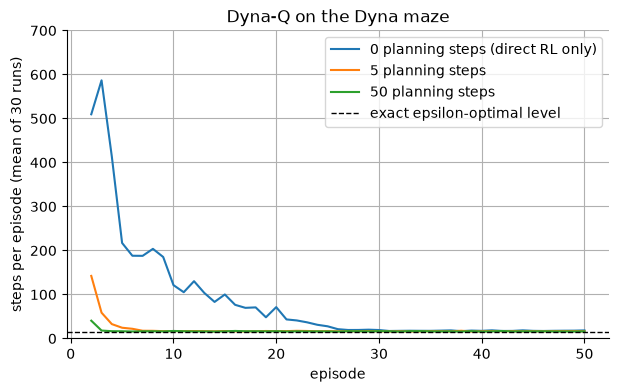

In [13]:
rescored = {"late level + 3 standard errors": threshold}
for m in RESCORE_MARGINS:
    rescored[f"late level + {m} steps"] = {n: plateau[n].mean() + m for n in PLAN_STEPS}
rescored[f"exact epsilon-optimal level + {RESCORE_MARGINS[-1]} steps"] = {
    n: h_eps_opt + RESCORE_MARGINS[-1] for n in PLAN_STEPS
}
print(
    "Episode from which the mean stays below the level, by rule (learning episodes before it in brackets, as the book counts):"
)
rescored_stays = {}
for rule, limits in rescored.items():
    rescored_stays[rule] = {n: episodes_needed(mean_steps[n], limits[n])[1] for n in PLAN_STEPS}
    print(f"  {rule:<46}" + "  ".join(f"n = {n}: {e} ({e - 1})" for n, e in rescored_stays[rule].items()))
print(f"Mean steps at episodes 40 and 50 for n = 0: {mean_steps[0][39]:.1f} and {mean_steps[0][49]:.1f}")
fig, ax = plt.subplots()
for n in PLAN_STEPS:
    ax.plot(
        np.arange(2, N_EPISODES + 1),
        mean_steps[n][1:],
        label=f"{n} planning steps" + (" (direct RL only)" if n == 0 else ""),
    )
ax.axhline(h_eps_opt, color="k", ls="--", lw=1, label="exact epsilon-optimal level")
ax.set(
    xlabel="episode",
    ylabel=f"steps per episode (mean of {N_REPS} runs)",
    title="Dyna-Q on the Dyna maze",
    ylim=STEPS_YLIM,
)
ax.legend()
plt.show()

### Reading the result

- **First episode.** The mean over 30 runs is 1088.1 steps, identical for every $n$. The exact expectation is 868.7 with standard deviation 789.2, so the exact standard error of a 30-run mean is 144.1 and the mean is 1.5 standard errors above the expectation: consistent with a random walk. The chapter's "about 1700" is 5.8 of these standard errors above the expectation, so the 30-run average of this maze does not give it; its episode-2 value for $n = 0$ (about 850, read off the plot by eye) is also well above the 509.6 here. Both fit better a single run, or one seed held fixed across repetitions, than a 30-run average: a single first episode exceeds 1700 steps with probability 0.128. This explanation is not tested (the chapter's code is not available). The check at the end uses the exact standard error, so its tolerance is 3 x 144.1 = 432 steps; a looser check would have passed a mean as large as 1301.
- **Planning speeds learning up, as in the chapter.** In episode 2 the mean is 509.6 steps for $n = 0$, 142.2 for $n = 5$ and 40.5 for $n = 50$. By episode 5 the values are 217.1, 24.5 and 16.5.
- **Episodes needed.** The rule of the previous section gives a settling episode of 30 for $n = 0$, 7 for $n = 5$ and 4 for $n = 50$ (first reached in episodes 27, 7 and 4); the chapter says about 25, 5 and 3. The gap is the rule, not the algorithm: with the late level plus 5 steps the episodes are 26, 7 and 3, with plus 10 steps 25, 5 and 3, and with the exact level plus 10 steps 26, 5 and 3 (all in the re-scoring printed above). The chapter's axis cannot resolve differences below about 10 steps (by eye). The chapter also counts learning episodes ("by the end of the third episode"), whereas the table reports the index of the first good episode; the learning episodes before it are 29, 6 and 3 under the first rule and 24, 4 and 2 under the third. The order $n = 50$ before $n = 5$ before $n = 0$ and the large gain from planning hold under every rule.
- **Late levels.** Episodes 41 to 50 average 17.74, 16.62 and 16.20 steps for $n = 0, 5, 50$, which is 1.86, 0.74 and 0.32 above the exact $\varepsilon$-optimal level of 15.88 (6.4, 3.2 and 1.7 standard errors). None is below the exact level, but the agents are not exactly at it. The $n = 0$ value is not a plateau: its mean is 17.4 at episode 40 and 18.4 at episode 50, so the first rule's reference moves with the window; the rules relative to the exact level avoid that. A possible reason is that the constant step size 0.1 keeps the action values noisy enough to flip near-ties between paths (explanation, not tested; so is whether longer runs would close the gap).
- **Model and planning checks.** Every model entry of every run equals the true transition. Planning alone on the model of one $n = 0$ run (184 observed pairs) cuts the Bellman residual from 0.872 to 0.0e+00, and the result equals value iteration on the same model (difference 0.0e+00, within the bound residual$/(1-\gamma)$): the planning backup computes what value iteration computes.
- The plot shows the three mean curves from episode 2 against the exact level (dashed); the $n = 0$ curve takes about 30 episodes to join the others, the $n = 5$ curve about 7 and the $n = 50$ curve about 4.

## 3. The policies after the second episode

Why do the planning agents learn so much faster? The chapter shows the policies of the $n = 0$ and $n = 50$ agents halfway through the second episode. This section does the same, and also shows the end of the second episode.

- An arrow marks the greedy action(s) of a cell; a cell whose four action values are equal has no arrow. The black square is the agent.
- Halfway means after half of the second episode's steps. The second episode's length is only known once it has run, so each agent is run twice with the same seeds; the two runs are identical (the output prints the check), and the second run keeps a copy of $Q$ at the two moments.
- One run per $n$ with its own seed, so the pictures are single draws, like the chapter's figure; the printed counts describe only these runs.
- *Cells with a greedy path* counts the cells from which following the first greedy action (while some value is nonzero) reaches G.

In [14]:
def reach_count(maze: Maze, Q: list[float]) -> int:
    """Number of cells from which following the first greedy action (while some value is nonzero) ends in the goal."""
    count = 0
    for s0 in np.flatnonzero(maze.free):
        s = s0
        for _ in range(maze.n_cells):
            q = Q[4 * s : 4 * s + 4]
            if s == maze.goal or max(q) == 0.0:
                break
            s = maze.nxt[4 * s + q.index(max(q))]
        count += s0 != maze.goal and s == maze.goal
    return int(count)


def draw_policy(ax: plt.Axes, maze: Maze, Q: list[float], agent_cell: int, title: str) -> None:
    """Arrows of the greedy action(s) in every cell with unequal action values; the black square is the agent."""
    for s in range(maze.n_cells):
        r, c = divmod(s, maze.w)
        q = Q[4 * s : 4 * s + 4]
        if maze.walls[r, c]:
            ax.add_patch(Rectangle((c, r), 1, 1, color="0.6"))
        elif max(q) > min(q):
            ax.text(c + 0.5, r + 0.5, "".join(ARROWS[a] for a in range(4) if q[a] == max(q)), ha="center", va="center")
    for s, label in ((maze.start, "S"), (maze.goal, "G")):
        ax.text(divmod(s, maze.w)[1] + 0.1, divmod(s, maze.w)[0] + 0.25, label, fontsize=8, weight="bold")
    ax.plot(agent_cell % maze.w + 0.5, agent_cell // maze.w + 0.5, "ks", ms=7)
    ax.set(
        xlim=(0, maze.w),
        ylim=(maze.h, 0),
        title=title,
        xticks=range(maze.w + 1),
        yticks=range(maze.h + 1),
        xticklabels=[],
        yticklabels=[],
    )
    ax.grid(True)

n = 0 : episodes of 373 and 1415 steps; cells with a greedy path to the goal / cells with a nonzero value, halfway through episode 2: (1, 1), at its end: (2, 2); replay identical: True
n = 50: episodes of 373 and 64 steps; cells with a greedy path to the goal / cells with a nonzero value, halfway through episode 2: (22, 22), at its end: (45, 45); replay identical: True


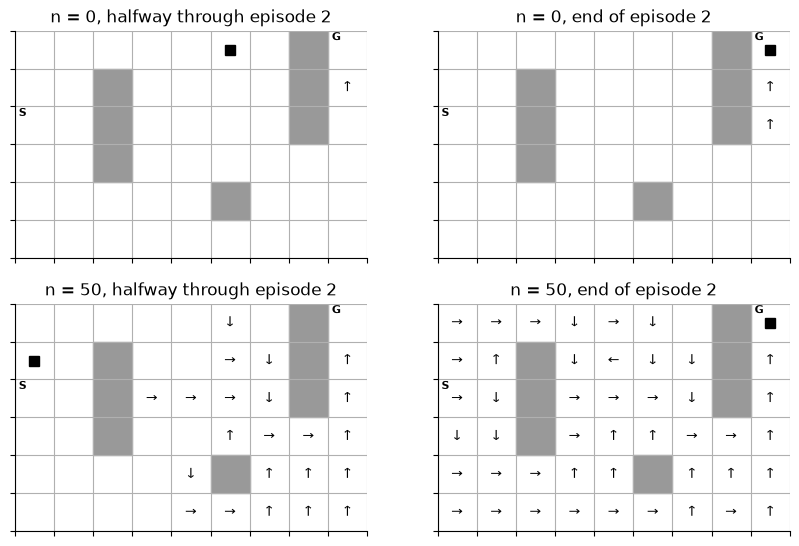

In [15]:
policy_shots, policy_counts, episode = {}, {}, SNAPSHOT_EPISODE - 1
for n in POLICY_STEPS:
    ((rng_act, rng_plan),) = rep_rngs(SEED_POLICY, 1)
    lengths, _ = run_episodes(maze, DynaQ(maze.n_cells, rng_act, rng_plan, n_plan=n), SNAPSHOT_EPISODE)
    moments = sorted({(episode, lengths[episode] // 2), (episode, lengths[episode])})
    ((rng_act, rng_plan),) = rep_rngs(SEED_POLICY, 1)
    replay, shots = run_episodes(
        maze, DynaQ(maze.n_cells, rng_act, rng_plan, n_plan=n), SNAPSHOT_EPISODE, frozenset(moments)
    )
    assert replay == lengths
    half, end = (shots[m] for m in moments)
    policy_shots[n] = (half, end)
    policy_counts[n] = [
        (reach_count(maze, Q), sum(max(Q[4 * s : 4 * s + 4]) > 0 for s in range(maze.n_cells))) for Q, _ in (half, end)
    ]
    print(
        f"n = {n:<2}: episodes of {lengths[0]} and {lengths[1]} steps; cells with a greedy path to the goal / cells with a nonzero value, halfway through episode {SNAPSHOT_EPISODE}: {policy_counts[n][0]}, at its end: {policy_counts[n][1]}; replay identical: {replay == lengths}"
    )
fig, axes = plt.subplots(2, 2, figsize=POLICY_FIGSIZE)
for row, n in enumerate(POLICY_STEPS):
    for col, (name, (Q, cell)) in enumerate(zip(("halfway through episode 2", "end of episode 2"), policy_shots[n])):
        draw_policy(axes[row, col], maze, Q, cell, f"n = {n}, {name}")
plt.show()

### Reading the result

- Without planning ($n = 0$), the second episode takes 1415 steps (the first took 373). Halfway through it one cell has a nonzero value and a greedy path to G: the cell next to the goal. At the end of the episode two cells have. The chapter says each episode adds one step to the policy.
- With planning ($n = 50$), the second episode takes only 64 steps. Halfway through it 22 cells already have a greedy path to G, and at its end 45 of the 46 non-goal cells do, while the agent is still near the start. The upper panels are $n = 0$, the lower panels $n = 50$; the arrows in the lower panels lead toward G.
- This agrees with the chapter's account: planning backups spread the goal's value backward through the model during the episode, whereas a backup without planning moves it by about one step. The panels are compared with the chapter's figure by eye (same layout and the same contrast; the exact arrows differ because the runs differ).

## 4. When the model is wrong: Dyna-Q+ on the blocking and shortcut mazes

A model learned from past experience can be stale when the environment changes. Two mazes of 6 rows and 9 columns, with a wall across row 4, show the two cases:

- **Blocking maze.** For the first 1000 time steps the wall has a gap at its right end; then the gap closes and one opens at the left end. The old route is now blocked: the model is *optimistic* (it promises a path that no longer exists), so acting on it exposes the mistake, because the agent bumps into the wall.
- **Shortcut maze.** For the first 3000 time steps the wall has a gap at the left end; then a second gap opens at the right end, giving a shorter route while the old one still works. The model is not optimistic but *pessimistic* (it hides the improvement): the agent keeps using the old route and rarely tries the new gap.

**Dyna-Q+** adds an exploration bonus to planning. For each pair it tracks $\tau$, the time steps since the pair was last tried in the real environment, and a planning backup treats the modeled reward $R$ as $R + \kappa \sqrt{\tau}$:

$$
Q(S,A) \leftarrow Q(S,A) + \alpha \Big[ R + \kappa \sqrt{\tau} + \gamma \max_a Q(S',a) - Q(S,A) \Big]
$$

The longer a pair has gone untested, the more it is worth testing in the plan. Two more changes from the chapter: planning may use actions never tried from a state, and their initial model is "leads back to the same cell with reward 0".

The chapter gives no parameters for these mazes. The choices here, fixed before running and not tuned:

- $\alpha = 1$ (the environment is deterministic), $\varepsilon = 0.1$, $\gamma = 0.95$, $n = 10$ planning steps, $\kappa = 0.001$; time horizons 3000 (change after 1000) and 6000 (change after 3000), read from the chapter's axes; maze geometry read from the figures by eye (start in column 4 of the bottom row, goal at the top right).
- A *time step* is one real step; reaching G returns the agent to the start without a separate step. If the agent stands in a cell that becomes a wall, it is moved to the start.
- $\tau$ is counted from the time step when the pair was last tried, or from step 0 for a pair never tried. The bonus enters planning backups only: not real backups and not action selection. The states available to planning are the ones the agent has stood in.
- 30 runs per agent, built the same way as in the Dyna maze experiment.

In [16]:
class DynaQPlus(DynaQ):
    """Dyna-Q+: planning backups use r + kappa sqrt(tau) for a pair untried for tau steps; every action of a visited state is plannable."""

    def __init__(self, *args, kappa: float, **kw):
        super().__init__(*args, **kw)
        self.kappa, self.last = kappa, [0] * len(self.Q)

    def remember(self, i: int, r: float, s2: int) -> None:
        super().remember(i, r, s2)
        self.last[i] = self.t

    def plan(self) -> None:
        """One planning backup on a random action of a random visited state, with the bonus kappa sqrt(tau) added to the reward."""
        j = 4 * self.visited[int(next(self.u_plan) * len(self.visited))] + int(next(self.u_plan) * 4)
        r, s2 = (self.model_r[j], self.model_s[j]) if self.model_s[j] >= 0 else (0.0, j // 4)
        self.backup(j, r + self.kappa * (self.t - self.last[j]) ** 0.5, s2)

In [17]:
def greedy_path_length(maze: Maze, Q: list[float], limit: int) -> int | None:
    """Steps from the start to the goal along the first greedy action, or None if that takes more than `limit` steps or meets a zero value."""
    s = maze.start
    for k in range(1, limit + 1):
        q = Q[4 * s : 4 * s + 4]
        if max(q) == 0.0:
            return None
        s = maze.nxt[4 * s + q.index(max(q))]
        if s == maze.goal:
            return k
    return None


def run_timed(envs: tuple[Maze, Maze], change_at: int, horizon: int, agent: Agent) -> tuple[np.ndarray, list]:
    """Play `horizon` time steps in `envs[0]`, then in `envs[1]` after step `change_at`; rewards per step and greedy path lengths at the change and the end."""
    maze, s, rewards, lengths = envs[0], envs[0].start, np.zeros(horizon), []
    for t in range(1, horizon + 1):
        a = agent.act(s)
        s2 = maze.nxt[4 * s + a]
        rewards[t - 1] = s2 == maze.goal
        agent.learn(s, a, rewards[t - 1], s2, t)
        s = maze.start if s2 == maze.goal else s2
        if t == change_at:
            lengths.append(greedy_path_length(maze, agent.Q, PATH_LIMIT))
            maze = envs[1]
            s = maze.start if maze.walls.ravel()[s] else s
    return rewards, lengths + [greedy_path_length(maze, agent.Q, PATH_LIMIT)]

In [18]:
change = {}
for task, (before, after, change_at, horizon) in TASKS.items():
    envs = (Maze(before), Maze(after))
    d_env = [int(shortest_distances(e)[e.start]) for e in envs]
    h_env = [expected_steps(e, eps_greedy_policy(optimal_q(e), EPS))[e.start] for e in envs]
    print(
        f"{task}: shortest path {d_env[0]} before the change and {d_env[1]} after; epsilon-optimal steps per episode {h_env[0]:.2f} and {h_env[1]:.2f}"
    )
    for label, (n, kappa) in AGENTS.items():
        cum, lens = [], []
        for rng_act, rng_plan in rep_rngs(SEED_CHANGE, CHANGE_REPS):
            args = (envs[0].n_cells, rng_act, rng_plan)
            agent = (
                DynaQPlus(*args, n_plan=n, alpha=CHANGE_ALPHA, kappa=kappa)
                if kappa
                else DynaQ(*args, n_plan=n, alpha=CHANGE_ALPHA)
            )
            rewards, lengths = run_timed(envs, change_at, horizon, agent)
            cum.append(np.cumsum(rewards))
            lens.append(lengths)
        change[task, label] = (np.array(cum), lens)
    change[task, "truth"] = (d_env, h_env)

blocking: shortest path 10 before the change and 16 after; epsilon-optimal steps per episode 11.26 and 17.92
shortcut: shortest path 16 before the change and 10 after; epsilon-optimal steps per episode 17.92 and 11.26


In [19]:
def cum_at(task: str, label: str, t: int) -> np.ndarray:
    """Cumulative reward of every run at time step `t`."""
    return change[task, label][0][:, t - 1]


def mean_se(x: np.ndarray) -> str:
    """Mean and standard error of `x` as text."""
    return f"{x.mean():6.1f} +- {x.std(ddof=1) / np.sqrt(len(x)):.1f}"


change_found, change_diff = {}, {}
for task, (_, _, change_at, horizon) in TASKS.items():
    d_env, h_env = change[task, "truth"]
    print(
        f"{task} maze, cumulative reward (mean +- standard error over {CHANGE_REPS} runs) at the change, midway and the end:"
    )
    for label in AGENTS:
        mid = (change_at + horizon) // 2
        n_found = [sum(lens[k] == d_env[k] for lens in change[task, label][1]) for k in (0, 1)]
        change_found[task, label] = n_found
        print(
            f"  {label:<20}"
            + "  ".join(mean_se(cum_at(task, label, t)) for t in (change_at, mid, horizon))
            + f"   greedy path is shortest: {n_found[0]} runs at the change, {n_found[1]} at the end"
        )
    diff = cum_at(task, "Dyna-Q+", horizon) - cum_at(task, "Dyna-Q", horizon)
    change_diff[task] = (diff.mean(), diff.std(ddof=1) / np.sqrt(CHANGE_REPS))
    print(
        f"  Dyna-Q+ minus Dyna-Q at the end (paired by seed): {mean_se(diff)}, {change_diff[task][0] / change_diff[task][1]:.1f} standard errors"
    )
    final = {
        label: FINAL_WINDOW
        * CHANGE_REPS
        / np.sum(change[task, label][0][:, -1] - change[task, label][0][:, -FINAL_WINDOW - 1])
        for label in AGENTS
    }
    print(
        "  steps per episode in the last 1000 steps (all runs pooled): "
        + ", ".join(f"{label} {v:.1f}" for label, v in final.items())
        + f"; epsilon-optimal levels {h_env[0]:.1f} (old path) and {h_env[1]:.1f} (new path)"
    )

blocking maze, cumulative reward (mean +- standard error over 30 runs) at the change, midway and the end:
  no planning (n = 0)    3.8 +- 1.0     5.5 +- 1.0     7.1 +- 1.0   greedy path is shortest: 2 runs at the change, 0 at the end
  Dyna-Q                41.6 +- 4.5    55.0 +- 5.9    82.3 +- 9.0   greedy path is shortest: 19 runs at the change, 11 at the end
  Dyna-Q+               60.4 +- 2.0    92.1 +- 1.7   140.8 +- 1.8   greedy path is shortest: 24 runs at the change, 8 at the end
  Dyna-Q+ minus Dyna-Q at the end (paired by seed):   58.5 +- 9.0, 6.5 standard errors
  steps per episode in the last 1000 steps (all runs pooled): no planning (n = 0) 612.2, Dyna-Q 36.5, Dyna-Q+ 20.5; epsilon-optimal levels 11.3 (old path) and 17.9 (new path)
shortcut maze, cumulative reward (mean +- standard error over 30 runs) at the change, midway and the end:
  no planning (n = 0)    5.6 +- 0.4    23.9 +- 3.1   112.0 +- 10.2   greedy path is shortest: 0 runs at the change, 22 at the end
  Dyna-Q 

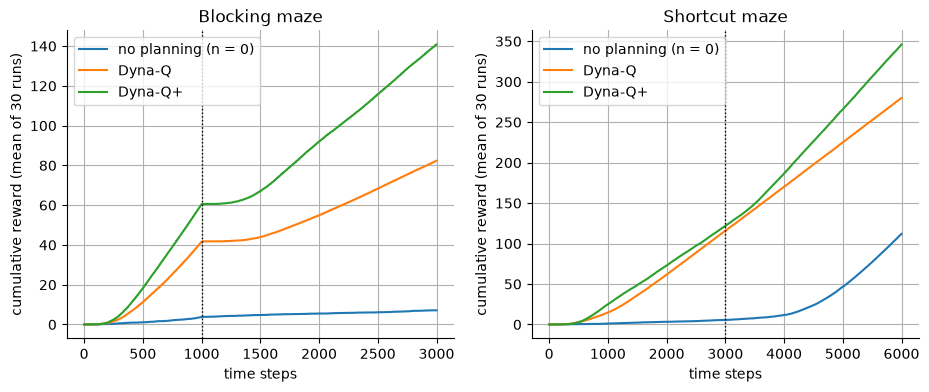

In [20]:
fig, axes = plt.subplots(1, 2, figsize=CHANGE_FIGSIZE)
for ax, (task, (_, _, change_at, horizon)) in zip(axes, TASKS.items()):
    for label in AGENTS:
        ax.plot(np.arange(1, horizon + 1), change[task, label][0].mean(axis=0), label=label)
    ax.axvline(change_at, color="k", ls=":", lw=1)
    ax.set(
        xlabel="time steps", ylabel=f"cumulative reward (mean of {CHANGE_REPS} runs)", title=f"{task.capitalize()} maze"
    )
    ax.legend()
plt.show()

### Reading the result

All values are cumulative reward, mean over 30 runs $\pm$ standard error.

- **Blocking maze.** At the change (step 1000) Dyna-Q has 41.6 $\pm$ 4.5, Dyna-Q+ 60.4 $\pm$ 2.0 and plain Q-learning 3.8 $\pm$ 1.0. At the end (step 3000): 82.3 $\pm$ 9.0, 140.8 $\pm$ 1.8 and 7.1 $\pm$ 1.0. Dyna-Q+ ends ahead of Dyna-Q by 58.5 $\pm$ 9.0 (paired by seed), 6.5 standard errors. The Dyna-Q and Dyna-Q+ curves flatten right after the change and rise again, as in the chapter (by eye). Recovery is slow for Dyna-Q: in the last 1000 steps it takes 36.5 steps per episode (pooled over runs) against 20.5 for Dyna-Q+; the $\varepsilon$-optimal levels are 11.3 steps for the old route and 17.9 for the new one.
- **Short route learned before the change.** The greedy path from the start is a shortest path (10 steps) in 19 of 30 Dyna-Q runs and 24 of 30 Dyna-Q+ runs at step 1000, and in 2 of 30 plain Q-learning runs. The chapter says all its agents found the short path within 1000 steps; plain Q-learning without planning has not done so here (the chapter's third agent is a different one).
- **The greedy-path count is a confounded measure for Dyna-Q+.** Its action values contain the planning bonus, so the greedy path need not be the path it follows. The printed counts show this: at the shortcut change Dyna-Q has a shortest greedy path in 27 of 30 runs and Dyna-Q+ in 16 of 30, and at the end of the blocking maze 11 against 8, although Dyna-Q+ has the higher reward in both mazes. Cumulative reward and steps per episode are the cleaner evidence; the greedy-path counts are reported as printed.
- **Shortcut maze.** At the change (step 3000): 115.9 $\pm$ 4.7 (Dyna-Q), 121.8 $\pm$ 1.1 (Dyna-Q+) and 5.6 $\pm$ 0.4 (Q-learning). At the end (step 6000): 279.9 $\pm$ 4.8, 346.0 $\pm$ 2.3 and 112.0 $\pm$ 10.2. Dyna-Q+ ends ahead of Dyna-Q by 66.1 $\pm$ 4.8 (13.7 standard errors).
- **Dyna-Q never finds the shortcut, as in the chapter.** In none of the 30 Dyna-Q runs is the final greedy path the shortcut (10 steps), and its steps per episode in the last 1000 steps (18.2) sit at the old route's $\varepsilon$-optimal level of 17.9. Dyna-Q+ has the shortcut as its greedy path in 24 of 30 runs (subject to the confound above) and takes 12.5 steps per episode, near the new route's level of 11.3. Plain Q-learning also ends with the shortcut in 22 of 30 runs; it is still learning the old maze at step 3000 (5.6 reward), so this is not evidence that it handles change better, and the reason is not tested.
- The plot shows both mean curves of cumulative reward with the change marked by the dotted line; its shapes match the chapter's two figures by eye (flat stretch after blocking, Dyna-Q+ above Dyna-Q after both changes); the chapter's Dyna-AC curve has no counterpart here.

## 5. Prioritized sweeping

Dyna-Q picks its simulated pairs without regard to their value, so early on almost every planning backup moves value between two zero-valued cells and changes nothing. Prioritized sweeping works backward from where values just changed. For the deterministic case:

1. choose $A$ by $\varepsilon$-greedy, execute it, observe $R, S'$; store $\mathrm{Model}(S,A) \leftarrow R, S'$ (there is no direct backup of the real transition);
2. compute the priority $P = \lvert R + \gamma \max_a Q(S',a) - Q(S,A) \rvert$, the size of the change a backup would make; if $P > \theta$, insert $(S,A)$ in a priority queue with priority $P$;
3. up to $n$ times while the queue is not empty: take the top pair, back it up, then for every pair $(\bar S, \bar A)$ the model says leads to $S$ (its predecessors) compute $P = \lvert \bar R + \gamma \max_a Q(S,a) - Q(\bar S,\bar A) \rvert$ with $\bar R$ the modeled reward, and insert it if $P > \theta$. A pair already queued keeps only its higher priority.

The queue is a heap with lazy deletion (an entry whose priority was superseded is skipped when it surfaces).

The chapter's experiment runs the Dyna maze at many grid resolutions and counts the backups until the optimal solution is found, with at most $n = 5$ backups per real step for both methods. The chapter does not say how the resolutions are made or what "optimal" means. Choices here:

- **Resolutions:** every cell becomes a $k \times k$ block of cells with $k = 1, 2, 3, 4$: 47, 188, 423 and 752 states (the chapter's axis has 47, 94, 186, 376, 752, ...; only 47 and 752 coincide, 186 is close to 188). The start is the top-left cell of the start block and the goal the top-right cell of the goal block.
- **Optimal:** the first time the greedy path from the start (first greedy action at every cell, a path through a zero value does not count) reaches the goal in exactly the shortest-path number of steps, found by breadth-first search.
- **Backups counted** are all Q backups: for Dyna-Q the real step's backup plus its 5 planning backups, for prioritized sweeping the queue backups (at most 5 per step). The backups made before the first arrival in G are recorded too.
- $\alpha = 1$, $\theta = 10^{-4}$, $\varepsilon = 0.1$, $\gamma = 0.95$; repetitions 30, 20, 12 and 8 for the four sizes, scaled down to keep the notebook fast.
- **Censoring.** A run that has not reached an optimal greedy path within 150,000 real steps is *censored*. The reason can be exploration: an agent that follows its best known route only tries other routes through its 10% random actions. Medians below use the runs that both methods finished (paired by seed, so each pair shares its acting draws).
- **Sign test.** In paired runs, how often does sweeping need fewer backups? If the two methods were equally likely to win a pair, the *p-value* is the probability of at least as many wins for sweeping as observed; a small p-value means the wins are not luck.

In [21]:
class PrioritizedSweeping(Agent):
    """Prioritized sweeping for a deterministic environment: a queue of pairs ordered by the size of the change a backup would make."""

    def __init__(self, *args, n_plan: int, theta: float = THETA, **kw):
        super().__init__(*args, **kw)
        self.n_plan, self.theta, self.heap, self.priority = n_plan, theta, [], {}
        self.pred = [set() for _ in range(len(self.Q) // 4)]

    def push(self, i: int, p: float) -> None:
        """Insert pair i with priority p if p > theta; a pair already queued keeps only the higher priority."""
        if p > self.theta and p > self.priority.get(i, 0.0):
            self.priority[i] = p
            heapq.heappush(self.heap, (-p, i))

    def pop(self) -> int:
        """Index of the highest-priority pair, or -1 if the queue is empty (entries superseded by a higher priority are skipped)."""
        while self.heap:
            neg, i = heapq.heappop(self.heap)
            if self.priority.get(i) == -neg:
                del self.priority[i]
                return i
        return -1

    def learn(self, s: int, a: int, r: float, s2: int, t: int) -> None:
        """One real step: model update and queueing of the pair, then up to `n_plan` queue backups with predecessor updates."""
        i = 4 * s + a
        self.model_s[i], self.model_r[i] = s2, r
        self.pred[s2].add(i)
        self.push(i, abs(r + self.gamma * max(self.Q[4 * s2 : 4 * s2 + 4]) - self.Q[i]))
        for _ in range(self.n_plan):
            if (j := self.pop()) < 0:
                break
            self.backup(j, self.model_r[j], self.model_s[j])
            s_j = j // 4
            q_max = max(self.Q[4 * s_j : 4 * s_j + 4])
            for k in self.pred[s_j]:
                if self.model_s[k] == s_j:
                    self.push(k, abs(self.model_r[k] + self.gamma * q_max - self.Q[k]))

In [22]:
def run_until_optimal(maze: Maze, agent: Agent, d: int, max_steps: int) -> tuple[int, int, int, int]:
    """Real steps, Q backups, backups at the first goal arrival and observed pairs, until the greedy path from the start is a shortest path (backups -1 if not within `max_steps`)."""
    s, t, first = maze.start, 0, None
    while t < max_steps:
        a = agent.act(s)
        s2 = maze.nxt[4 * s + a]
        t += 1
        agent.learn(s, a, float(s2 == maze.goal), s2, t)
        first = agent.backups if first is None and s2 == maze.goal else first
        if greedy_path_length(maze, agent.Q, d) == d:
            return t, agent.backups, first, sum(m >= 0 for m in agent.model_s)
        s = maze.start if s2 == maze.goal else s2
    return t, -1, first or agent.backups, sum(m >= 0 for m in agent.model_s)

In [23]:
sweep = {}
for k, reps in zip(SWEEP_SCALES, SWEEP_REPS):
    big = Maze(DYNA_MAZE, k)
    d_big = int(shortest_distances(big)[big.start])
    for name, cls in (("Dyna-Q", DynaQ), ("prioritized sweeping", PrioritizedSweeping)):
        out = []
        for rng_act, rng_plan in rep_rngs(SEED_SWEEP, reps):
            agent = cls(big.n_cells, rng_act, rng_plan, n_plan=SWEEP_PLAN, alpha=SWEEP_ALPHA)
            out.append(run_until_optimal(big, agent, d_big, SWEEP_MAX_STEPS))
        sweep[k, name] = np.array(out, dtype=float)
    sweep[k, "info"] = (int(big.free.sum()), d_big)

In [24]:
sweep_rows = {}
for k in SWEEP_SCALES:
    dq, ps = sweep[k, "Dyna-Q"], sweep[k, "prioritized sweeping"]
    both = (dq[:, 1] >= 0) & (ps[:, 1] >= 0)
    d, p = dq[both], ps[both]
    sweep_rows[k] = dict(
        states=sweep[k, "info"][0],
        shortest=sweep[k, "info"][1],
        finished=(int((dq[:, 1] >= 0).sum()), int((ps[:, 1] >= 0).sum()), len(dq)),
        pairs=int(both.sum()),
        dq=np.median(d[:, 1]),
        ps=np.median(p[:, 1]),
        dq_after=np.median(d[:, 1] - d[:, 2]),
        ps_after=np.median(p[:, 1] - p[:, 2]),
        ratio=np.median(d[:, 1] / p[:, 1]),
        ratio_after=np.median(d[:, 1] - d[:, 2]) / np.median(p[:, 1] - p[:, 2]),
        observed=tuple(
            np.mean(ps[mask, 3]) / (4 * sweep[k, "info"][0]) if mask.any() else np.nan
            for mask in (ps[:, 1] >= 0, ps[:, 1] < 0)
        ),
        fewer=int((p[:, 1] < d[:, 1]).sum()),
    )

Runs finished by Dyna-Q / by prioritized sweeping / started; medians over the runs both finished (paired by seed):
states  shortest  finished   pairs   backups Dyna-Q   backups sweeping   median ratio   after first goal: Dyna-Q vs sweeping (ratio)   sweeping fewer
    47        14   28/29/30      28            10323                155           60.8                   2541 vs 150    (16.9)    28 of 28
   188        29   20/16/20      16            42504                689           64.9                  14937 vs 684    (21.8)    16 of 16
   423        44   12/10/12      10           106002               1598           61.0                  43257 vs 1594   (27.1)    10 of 10
   752        59    8/ 5/8        5           199134               2945           69.1                 105846 vs 2940   (36.0)     5 of 5
Share of the 4 x states pairs that sweeping had observed when it stopped (finished runs / censored runs):
    47 states: 0.863 / 0.851
   188 states: 0.842 / 0.717
   423 states: 0

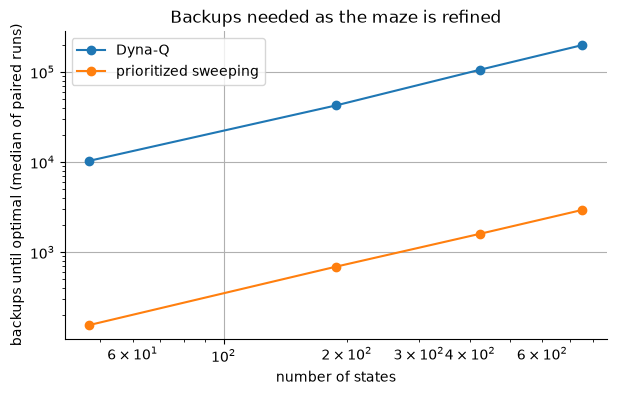

In [25]:
print(
    "Runs finished by Dyna-Q / by prioritized sweeping / started; medians over the runs both finished (paired by seed):"
)
print(
    "states  shortest  finished   pairs   backups Dyna-Q   backups sweeping   median ratio   after first goal: Dyna-Q vs sweeping (ratio)   sweeping fewer"
)
for r in sweep_rows.values():
    print(
        f"{r['states']:>6}  {r['shortest']:>8}  {r['finished'][0]:>3}/{r['finished'][1]:>2}/{r['finished'][2]:<3}  {r['pairs']:>5}   {r['dq']:>14.0f}   {r['ps']:>16.0f}   {r['ratio']:>12.1f}   "
        f"{r['dq_after']:>20.0f} vs {r['ps_after']:<6.0f} ({r['ratio_after']:.1f})   {r['fewer']:>3} of {r['pairs']}"
    )
print("Share of the 4 x states pairs that sweeping had observed when it stopped (finished runs / censored runs):")
for r in sweep_rows.values():
    print(f"  {r['states']:>4} states: {r['observed'][0]:.3f} / {r['observed'][1]:.3f}")
fewer_all, pairs_all = sum(r["fewer"] for r in sweep_rows.values()), sum(r["pairs"] for r in sweep_rows.values())
sign_p = stats.binomtest(fewer_all, pairs_all, 0.5, alternative="greater").pvalue
print(
    f"Sign test over all paired runs: sweeping needed fewer backups in {fewer_all} of {pairs_all} (one-sided p = {sign_p:.1e})"
)
fig, ax = plt.subplots()
for name, key in (("Dyna-Q", "dq"), ("prioritized sweeping", "ps")):
    ax.plot([r["states"] for r in sweep_rows.values()], [r[key] for r in sweep_rows.values()], "o-", label=name)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="number of states",
    ylabel="backups until optimal (median of paired runs)",
    title="Backups needed as the maze is refined",
)
ax.legend()
plt.show()

### Reading the result

- Prioritized sweeping needs far fewer backups than Dyna-Q at every size (median over the paired runs): 10,323 for Dyna-Q against 155 for sweeping at 47 states, 42,504 against 689 at 188, 106,002 against 1598 at 423, 199,134 against 2945 at 752. The median per-run ratio is 60.8, 64.9, 61.0 and 69.1. In all 59 paired runs sweeping used fewer (sign test p = 1.7e-18).
- Part of this is the wasted early planning. Dyna-Q spends 5 backups per step before the goal has ever been reached, when every backup changes nothing, while the queue of sweeping is empty then. Counting only the backups after the first arrival in G, the medians are 2541 against 150, 14,937 against 684, 43,257 against 1594 and 105,846 against 2940, a ratio of 16.9, 21.8, 27.1 and 36.0. The gap is real but depends on what is counted.
- **Agreement with the chapter.** Sweeping wins at every size and both curves rise with the number of states, as in the chapter's figure. Read off that figure by eye (rough values), Dyna-Q needs about 2e4, 7e4 and 1.4e5 backups and sweeping about 150, 1e3 and 4.5e4 at 47, 186 and 376 states: a ratio of about 130 at 47 states, about 55 at 186 and only a few at 376 and beyond, which is the "often 5 to 10 times" of the chapter's text. Here the sweeping counts match at the smallest size (155 against about 150) and the ratio is similar at 47 and 188 states (60.8 and 64.9), but it does not shrink at larger sizes: 61.0 at 423 and 69.1 at 752 states. So the notebook disagrees with the chapter at 376 states and beyond. A likely reason is that my "optimal" criterion (the first moment the greedy path from the start has the shortest length) is lenient, while the chapter's criterion is unknown; also the chapter's resolutions double the state count and mine use blocks. Neither is tested.
- **Censoring.** Dyna-Q finished 28 of 30 runs at 47 states and every run at the other sizes (20, 12 and 8); it was censored in 2 of 70 runs. Sweeping finished 29 of 30, 16 of 20, 10 of 12 and 5 of 8, so it was censored in 10 of 70. The censored sweeping runs had observed a smaller share of their state-action pairs when they stopped: 0.717, 0.746 and 0.581 against 0.842, 0.829 and 0.862 in the finished runs at 188, 423 and 752 states (at 47 states, one censored run, 0.851 against 0.863). A likely reason is that a sweeping agent settles on the best route it knows and only leaves it through its 10% random actions (explanation, not tested); why Dyna-Q is censored less often is not tested either. The medians use only the runs both finished, which favors runs that explored well, and at 752 states only 5 pairs remain.
- The plot shows the median backups against the number of states on logarithmic axes: both curves rise, and the sweeping curve stays below the Dyna-Q curve at all four sizes by the factors above.

## 6. Full versus sample backups

Backups for $q_*$ differ in how they use the model. For a pair with $b$ possible next states (the *branching factor*), all equally likely, a **full backup** averages over all of them and a **sample backup** uses one:

$$
Q(s,a) \leftarrow \sum_{s',r} \hat p(s',r \mid s,a)\big[r + \gamma \max_{a'} Q(s',a')\big]
\qquad\text{versus}\qquad
Q(s,a) \leftarrow Q(s,a) + \alpha\big[R + \gamma \max_{a'} Q(S',a') - Q(s,a)\big]
$$

- The full backup is exact given the successor values but costs $b$ evaluations of $\max_{a'} Q(s',a')$; the sample backup costs one and carries sampling error. With one possible next state and $\alpha = 1$ they are the same.
- With sample averages, $\alpha = 1/t$ at the $t$-th backup, the estimate is the mean of the $t$ sampled successor values. If the successor values have population variance $(b-1)/b$ (so a single sample is already off by $\sqrt{(b-1)/b}$, close to the initial error of 1), the root-mean-square (RMS) error after $t$ sample backups is

$$
\sqrt{\frac{b-1}{b\,t}}
$$

while the full backup gives error 0 after $b$ evaluations. The question is whether to spend a fixed amount of computation on a few full backups or on many sample backups.

The chapter derives the formula without saying how the successor values arise. The simulation here draws them independently from a standard normal distribution for each of 2000 repetitions: the error of the sample mean is then, for given values, their spread divided by $\sqrt{t}$, and averaged over draws the squared spread is exactly $(b-1)/b$. The truth is therefore the closed form. The simulation compares it with sampling with replacement for $b = 2, 10, 100, 1000$ and $t$ up to $2b$ (27 points).

The tolerance for each point is a multiple of the standard error of the simulated RMS error (from the spread of the squared errors across repetitions). With 27 simultaneous comparisons the limit is a *Bonferroni limit*: the two-sided normal quantile at the level 0.05 divided by 27. The 0.05 is the *family-wise* level, the probability that any of the 27 points falls outside its limit when the formula is right; Bonferroni guarantees it is at most 0.05.

In [26]:
def full_backup(successor_values: np.ndarray) -> tuple[float, int]:
    """Full backup of a pair with equally likely successors: the exact mean of their values, at a cost of b evaluations of max Q."""
    return float(successor_values.mean()), len(successor_values)


def sample_backups(successor_values: np.ndarray, t: int, rng: np.random.Generator) -> np.ndarray:
    """`t` sample backups Q <- Q + (1/t')(x - Q) on one pair, each from one random successor; returns Q after each (cost 1 each)."""
    q, out = 0.0, np.empty(t)
    for step in range(1, t + 1):
        q += (successor_values[rng.integers(len(successor_values))] - q) / step
        out[step - 1] = q
    return out

In [27]:
seed_values, seed_check, seed_sim = np.random.SeedSequence(SEED_BACKUP).spawn(3)
x = np.random.default_rng(seed_values).standard_normal(CHECK_SUCCESSORS)
path = sample_backups(x, CHECK_SAMPLES, np.random.default_rng(seed_check))
picked = np.random.default_rng(seed_check).integers(len(x), size=CHECK_SAMPLES)
mean_path_gap = np.abs(path - np.cumsum(x[picked]) / np.arange(1, CHECK_SAMPLES + 1)).max()
print(
    f"Checkpoint (consistency of two code paths): sample backups with step size 1/t equal the running sample mean of the same draws, largest difference {mean_path_gap:.1e}"
)
print(
    f"A full backup of this pair costs {full_backup(x)[1]} evaluations of max Q and returns the exact mean {full_backup(x)[0]:.4f}; a sample backup costs 1"
)

Checkpoint (consistency of two code paths): sample backups with step size 1/t equal the running sample mean of the same draws, largest difference 1.1e-16
A full backup of this pair costs 10 evaluations of max Q and returns the exact mean 0.1438; a sample backup costs 1


In [28]:
rng_sim = np.random.default_rng(seed_sim)
rows = []
for b in BACKUP_B:
    ts = sorted({t for t in BACKUP_T if t <= 2 * b} | {b, 2 * b})
    values = rng_sim.standard_normal((BACKUP_REPS, b))
    picks = rng_sim.integers(b, size=(BACKUP_REPS, 2 * b), dtype=np.int32)
    running = np.cumsum(np.take_along_axis(values, picks, 1), axis=1) / np.arange(1, 2 * b + 1)
    sq_err = (running - values.mean(axis=1, keepdims=True)) ** 2
    for t in ts:
        rms = np.sqrt(sq_err[:, t - 1].mean())
        se = sq_err[:, t - 1].std(ddof=1) / np.sqrt(BACKUP_REPS) / (2 * rms)
        rows.append((b, t, rms, np.sqrt((b - 1) / (b * t)), se))

In [29]:
z_back = z_limit(len(rows))
worst_z = max(abs(r[2] - r[3]) / r[4] for r in rows)
print(
    f"{len(rows)} (b, t) points; root-mean-square error of sample backups over {BACKUP_REPS} random successor-value draws against sqrt((b-1)/(b t)): largest difference {worst_z:.2f} standard errors (Bonferroni limit {z_back:.2f})"
)
print("      b       t    simulated     formula")
for b, t, rms, formula, se in rows:
    if t in BACKUP_SHOWN_T or t in (b, 2 * b):
        print(f"{b:>7} {t:>7} {rms:>12.4f} {formula:>11.4f}" + (f"   (t = {t // b} b)" if t % b == 0 else ""))
print(f"Checkpoint: the simulated error matches sqrt((b-1)/(b t)) at all {len(rows)} points:", worst_z < z_back)
by_point = {(r[0], r[1]): r[2] for r in rows}
b_big = BACKUP_B[-1]
for n_pairs in SPREAD_PAIRS:
    print(
        f"With b = {b_big}, one full backup's cost spread over {n_pairs} pairs gives each {b_big // n_pairs} sample backups, error {by_point[b_big, b_big // n_pairs]:.3f} per pair; "
        f"one full backup on one pair leaves the other {n_pairs - 1} at error 1, root-mean-square {np.sqrt((n_pairs - 1) / n_pairs):.3f} over the {n_pairs}"
    )

27 (b, t) points; root-mean-square error of sample backups over 2000 random successor-value draws against sqrt((b-1)/(b t)): largest difference 1.88 standard errors (Bonferroni limit 3.11)
      b       t    simulated     formula
      2       1       0.7087      0.7071
      2       2       0.4999      0.5000   (t = 1 b)
      2       4       0.3530      0.3536   (t = 2 b)
     10       1       0.9568      0.9487
     10      10       0.2968      0.3000   (t = 1 b)
     10      20       0.2124      0.2121   (t = 2 b)
    100       1       1.0177      0.9950
    100      10       0.3205      0.3146
    100     100       0.0999      0.0995   (t = 1 b)
    100     200       0.0701      0.0704   (t = 2 b)
   1000       1       0.9868      0.9995
   1000      10       0.3117      0.3161
   1000     100       0.0986      0.0999
   1000    1000       0.0309      0.0316   (t = 1 b)
   1000    2000       0.0221      0.0223   (t = 2 b)
Checkpoint: the simulated error matches sqrt((b-1)/(b t)) a

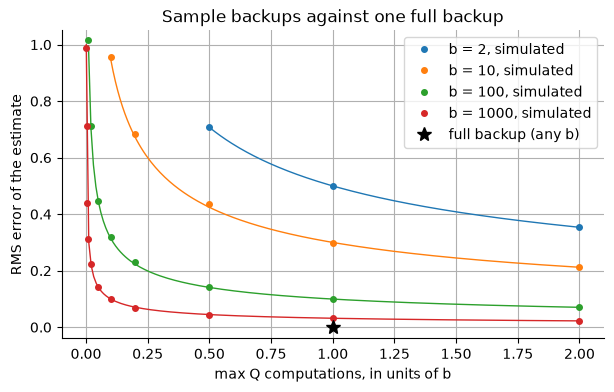

In [30]:
fig, ax = plt.subplots()
for i, b in enumerate(BACKUP_B):
    pts = [r for r in rows if r[0] == b]
    ax.plot([r[1] / b for r in pts], [r[2] for r in pts], "o", ms=4, color=f"C{i}", label=f"b = {b}, simulated")
    grid = np.linspace(1 / b, 2, CURVE_POINTS)
    ax.plot(grid, np.sqrt((b - 1) / (b * grid * b)), lw=1, color=f"C{i}")
ax.plot([1], [0], "k*", ms=10, label="full backup (any b)")
ax.set(
    xlabel="max Q computations, in units of b",
    ylabel="RMS error of the estimate",
    title="Sample backups against one full backup",
    ylim=BACKUP_YLIM,
)
ax.legend()
plt.show()

### Reading the result

- The simulated RMS errors follow $\sqrt{(b-1)/(bt)}$: the largest difference over the 27 points is 1.88 standard errors, inside the Bonferroni limit of 3.11. For $b = 1000$: 0.9868 against 0.9995 for a single sample ($t = 1$), 0.3117 against 0.3161 at $t = 10$, 0.0986 against 0.0999 at $t = 100$, 0.0309 against 0.0316 at $t = b$ and 0.0221 against 0.0223 at $t = 2b$.
- At the cost of one full backup ($t = b$) the sample estimate still has error 0.4999 for $b = 2$, 0.2968 for $b = 10$, 0.0999 for $b = 100$ and 0.0309 for $b = 1000$, against 0 for the full backup. For one pair, the full backup is better when its cost can be afforded.
- Computation is usually the limit. With $b = 1000$, the cost of one full backup spread over 100 pairs gives each 10 sample backups and an error of 0.312 for every pair, while one full backup on a single pair leaves the other 99 pairs at error 1, an RMS of 0.995 over the 100 pairs. Spread over 10 pairs (100 samples each) the error is 0.099 per pair against 0.949. This is the chapter's point: many sample backups at many pairs beat full backups at a few when the branching factor is large. It uses the formula, whose points were simulated above, plus the convention that an unbacked pair keeps error 1.
- The plot shows simulated points on the formula's curves for the four branching factors; the star is the full backup. The chapter's second argument, that sample backups also make successor values accurate sooner, needs backups that chain through successor estimates; it is not simulated here.
- The chapter's version of this figure has branching factors up to 10,000; here up to 1000. The comparison with the chapter's curves is by eye.

## 7. Checkpoints

Each line is an assertion against an exact value, a derived tolerance or an ordering; a silent regression fails the run. Some checks are weak by construction and say so in their text: they depend on a chosen rule or on the hyperparameters invented here, or they do not show that an agent reaches the exact level. The table gives the notebook's results next to their truth or the chapter's number (by eye where the chapter gives a figure).

In [31]:
z_first = (first_mean - h_random) / first_se
ratios = [r["ratio"] for r in sweep_rows.values()]
checks = [
    ("47 states, shortest path 14 steps, and v_* = gamma^(d-1), from two independent computations", maze_ok),
    (
        f"first-episode mean within {Z_CLAIM} exact standard errors ({Z_CLAIM * first_se:.0f} steps) of the exact expectation",
        abs(z_first) < Z_CLAIM,
    ),
    ("first episode identical for every n", first_equal),
    ("every learned model entry equals the true transition", model_exact),
    ("planning alone reaches the value-iteration solution of the learned model within the residual bound", plan_ok),
    (
        f"no late level lies below the exact epsilon-optimal level by more than the Bonferroni limit {z_limit(len(PLAN_STEPS)):.2f} standard errors (weak: the agents are {plateau_z[0]:.1f}, {plateau_z[5]:.1f} and {plateau_z[50]:.1f} standard errors above it, so this does not show they reach it)",
        all(plateau_z[n] > -z_limit(len(PLAN_STEPS)) for n in PLAN_STEPS),
    ),
    (
        "weak, depends on the rule: episodes to stay below the late level + 3 standard errors: n = 50 before n = 5 before n = 0",
        needed[50][1] < needed[5][1] < needed[0][1],
    ),
    (
        "n = 50 has more cells with a greedy path halfway through episode 2 than n = 0 at its end",
        policy_counts[50][0][0] > policy_counts[0][1][0],
    ),
    (
        f"blocking maze: Dyna-Q+ gains more than {Z_CLAIM} standard errors over Dyna-Q (paired; depends on the hyperparameters chosen here)",
        change_diff["blocking"][0] > Z_CLAIM * change_diff["blocking"][1],
    ),
    (
        f"shortcut maze: Dyna-Q+ gains more than {Z_CLAIM} standard errors over Dyna-Q (paired; depends on the hyperparameters chosen here)",
        change_diff["shortcut"][0] > Z_CLAIM * change_diff["shortcut"][1],
    ),
    (
        "shortcut maze: no Dyna-Q run ends with the shortcut as its greedy path (depends on the hyperparameters chosen here)",
        change_found["shortcut", "Dyna-Q"][1] == 0,
    ),
    (
        f"prioritized sweeping needs fewer backups in the paired runs (sign test below {FWER})",
        sign_p < FWER and min(ratios) > 1,
    ),
    ("sample-backup error equals sqrt((b-1)/(b t)) at every simulated point", worst_z < z_back),
    ("consistency of two code paths: incremental 1/t sample backups equal the running mean", mean_path_gap < AGREE_TOL),
]

In [32]:
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)
print(f"\n{'quantity':<64}{'result':>8}  truth / book")
for name, result, truth in [
    ("shortest path from the start (steps)", f"{d_star}", f"{BOOK_SHORTEST}"),
    (
        f"first-episode steps, mean of {N_REPS} runs (book: one figure)",
        f"{steps[0][:, 0].mean():.0f}",
        f"{h_random:.0f} exact; ~{BOOK_FIRST_EPISODE}",
    ),
    *[
        (f"episodes to stay below late level + 3 SE, n = {n}", f"{needed[n][1]}", book)
        for n, book in zip(PLAN_STEPS, BOOK_EPISODES)
    ],
    *[(f"late steps per episode, n = {n}", f"{plateau[n].mean():.2f}", f"{h_eps_opt:.2f} exact") for n in PLAN_STEPS],
    ("blocking: Dyna-Q+ minus Dyna-Q, cumulative reward", f"{change_diff['blocking'][0]:.1f}", "> 0 (figure)"),
    ("shortcut: Dyna-Q+ minus Dyna-Q, cumulative reward", f"{change_diff['shortcut'][0]:.1f}", "> 0 (figure)"),
    *[
        (
            f"sweeping: Dyna-Q backups / sweeping backups, {r['states']} states",
            f"{r['ratio']:.0f}",
            f"{BOOK_SWEEP_RATIO} (text)",
        )
        for r in sweep_rows.values()
    ],
    ("sample backups: largest deviation from the formula (std. errors)", f"{worst_z:.2f}", f"< {z_back:.2f}"),
]:
    print(f"{name:<64}{result:>8}  {truth}")

PASS 47 states, shortest path 14 steps, and v_* = gamma^(d-1), from two independent computations
PASS first-episode mean within 3 exact standard errors (432 steps) of the exact expectation
PASS first episode identical for every n
PASS every learned model entry equals the true transition
PASS planning alone reaches the value-iteration solution of the learned model within the residual bound
PASS no late level lies below the exact epsilon-optimal level by more than the Bonferroni limit 2.39 standard errors (weak: the agents are 6.4, 3.2 and 1.7 standard errors above it, so this does not show they reach it)
PASS weak, depends on the rule: episodes to stay below the late level + 3 standard errors: n = 50 before n = 5 before n = 0
PASS n = 50 has more cells with a greedy path halfway through episode 2 than n = 0 at its end
PASS blocking maze: Dyna-Q+ gains more than 3 standard errors over Dyna-Q (paired; depends on the hyperparameters chosen here)
PASS shortcut maze: Dyna-Q+ gains more than 